# Final 1 – Cleaning van de Citi Bike-data: van 44 zip-bestanden naar één modeltabel

| | |
|---|---|
| **Auteur(s)** | Kobe Vandenberk |
| **Wat** | Alle stappen om de ruwe ritdata van Citi Bike (juni 2013 – september 2026) om te zetten naar de tabel waarop het model traint: vertrekken per zone per uur, met het weer en het aanbod erbij. Bij elke stap: wat we vaststelden, wat we kozen en **waarom**. |
| **Input** | alle NYC-bestanden van `https://s3.amazonaws.com/tripdata/`, Open-Meteo archive API |
| **Output** | `data/model_table.parquet`, `data/zones.json`, `data/station_zones.parquet` (in de map `citi_bike/Kobe/data`) |
| **Volgende stap** | `02_analyse_en_modellen.ipynb` |
| **GenAI** | Code en tekst opgesteld met hulp van Claude; keuzes en resultaten nagekeken door Kobe. |

## Wat willen we voorspellen?
**Hoeveel Citi Bikes vertrekken er in een bepaalde zone van New York in een bepaald uur?** Dat moet Citi Bike weten om fietsen op tijd te herverdelen: een leeg station in de spits is een gemiste groene rit (thema *Going green*).

Daarvoor hebben we per **zone** en per **uur** het aantal **vertrekken** nodig, samen met wat op dat moment bekend is: kalender, weer en hoe groot het netwerk in die zone is. De ruwe data bevat individuele ritten (329 miljoen). Dit notebook brengt ze naar die vorm.

## Overzicht van de keuzes
| § | Probleem in de data | Keuze |
|---|---|---|
| 1 | 44 NYC-bestanden + 133 Jersey City-bestanden | alle NYC-bestanden, Jersey City niet |
| 2 | jaarbestanden bevatten sommige maanden twee keer | per maand één versie |
| 3 | drie generaties kolomnamen | omzetten naar het schema van vandaag |
| 4 | drie datumnotaties, wisselend per bestand | notatie per stuk bepalen |
| 5 | 329 miljoen ritten passen niet in het geheugen | in stukken lezen en meteen samenvatten |
| 6 | ritten zonder start, zonder einde, met rare duur, "dubbele" rijen | vertrek = starttijd + startstation + locatie in NYC |
| 7 | station-id's als getal opgeslagen; twee stelsels van id's | id's herstellen; stations via hun **locatie** behandelen |
| 8 | interne locaties, Jersey City/Hoboken | weglaten |
| 9 | dagen waarop het systeem dicht was | weglaten |
| 10 | 2.400 stations, te veel ruis per station | 30 zones (KMeans) op het netwerk van vandaag |
| 11 | het netwerk groeide van 330 naar 2.400 stations | aantal actieve stations per zone als kenmerk; uren zonder aanbod weglaten |
| 12 | uren zonder vertrek staan nergens in de data | volledig rooster zone × uur, met 0 |
| 13 | weer ontbreekt in de ritdata | uurlijks weer (Open-Meteo), inclusief sneeuwhoogte |
| 14 | hoe meten we eerlijk? | test = laatste 12 maanden; tunen met backtesting |

Alle verwerkingscode staat in `../citibike.py`, zodat dit notebook, de modelnotebooks en `train.py` (het script dat het model voor de API maakt) exact hetzelfde doen.

## 0. Imports

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))          # citibike.py staat in citi_bike/Kobe
import citibike as cb

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
GREEN, ORANGE, INK = "#2f6f4f", "#c47f00", "#17201b"
pd.set_option("display.max_columns", 30)
print("Data-map:", cb.DATA_DIR)

Data-map: C:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CloudAI-Challenge\citi_bike\Kobe\data


## 1. Welke bestanden?
**Vaststelling:** de officiële bucket bevat drie soorten bestanden:
- **2013–2023**: één zip per jaar;
- **vanaf 2024**: één zip per maand;
- **`JC-…`**: Jersey City, een apart Citi Bike-systeem aan de overkant van de Hudson.

In [2]:
bucket = cb.list_bucket()
files = cb.nyc_files(bucket)
jc = bucket[bucket["file"].str.startswith("JC")]
print(f"NYC: {len(files)} bestanden, {files['bytes'].sum() / 1e9:.1f} GB ({files['period'].iloc[0]} t/m {files['period'].iloc[-1]})")
print(f"Jersey City: {len(jc)} bestanden, {jc['bytes'].sum() / 1e9:.2f} GB")

NYC: 44 bestanden, 32.5 GB (2013 t/m 202609)
Jersey City: 133 bestanden, 0.22 GB


**Keuze:** we gebruiken **alle** NYC-bestanden en **geen** Jersey City-bestanden.

**Waarom alle jaren?** In een eerste studie gebruikten we alleen 2024. Het beste model maakte toen de grootste fouten op zeldzame dagen (Kerstmis, Thanksgiving, zware regen): in één jaar zit van elke feestdag maar één voorbeeld. Met 13 jaar heeft het model er telkens een tiental. In `02_analyse_en_modellen` meten we of dat echt helpt.

**Waarom geen Jersey City?** Dat is een ander systeem met eigen stations en eigen klanten. De vraag in Manhattan of Brooklyn hangt er niet van af, en de API voorspelt alleen voor New York.

### Downloaden met controle
Elk bestand wordt eerst naar een `.part`-bestand geschreven en pas hernoemd als de grootte klopt: een afgebroken download wordt zo nooit voor een geldige zip aangezien. Daarna berekenen we een **SHA-256 checksum** en bewaren die in `manifest.json`, zodat iedereen kan controleren dat hij exact dezelfde data gebruikt. Bestanden die al volledig aanwezig zijn, worden overgeslagen.

In [3]:
manifest = cb.download_all()
print(f"{len(manifest)} bestanden, {manifest['bytes'].sum() / 1e9:.1f} GB, {manifest['csv_files'].str.len().sum()} CSV's")
manifest["status"].value_counts()

2013-citibike-tripdata.zip           al aanwezig  0.33 GB,  17 CSV's (0 s)


2014-citibike-tripdata.zip           al aanwezig  0.22 GB,  12 CSV's (0 s)


2015-citibike-tripdata.zip           al aanwezig  0.28 GB,  16 CSV's (0 s)


2016-citibike-tripdata.zip           al aanwezig  0.44 GB,  20 CSV's (1 s)


2017-citibike-tripdata.zip           al aanwezig  0.56 GB,  20 CSV's (1 s)


...

202607-citibike-tripdata.zip         al aanwezig  0.97 GB,   5 CSV's (2 s)


202608-citibike-tripdata.zip         al aanwezig  1.02 GB,   6 CSV's (2 s)


202609-citibike-tripdata.zip         al aanwezig  0.97 GB,   5 CSV's (1 s)


44 bestanden, 32.5 GB, 426 CSV's


status
al aanwezig    44
Name: count, dtype: int64

## 2. Dezelfde maand twee keer in één bestand
**Vaststelling:** de jaarbestanden zijn mappen met CSV's (of zip's met CSV's) per maand. In het bestand van 2013 staat elke maand twee keer: één keer als los bestand (`201309-citibike-tripdata.csv`) en één keer in een maandmap, opgesplitst (`9_September/201309-citibike-tripdata_1.csv` + `_2.csv`). Zijn dat echt dezelfde ritten?

In [4]:
versions = {}
with ZipFile(cb.RAW_DIR / "2013-citibike-tripdata.zip") as archive:
    for full, holder, name in cb._walk_zip(archive):
        if cb.csv_month(full) == "201309":
            with holder.open(name) as handle:
                part = cb.standardize_columns(pd.read_csv(handle, dtype=str))
            versions.setdefault("los bestand" if full.count("/") == 1 else "maandmap", []).append(part)
versions = {k: pd.concat(v, ignore_index=True) for k, v in versions.items()}
a, b = (cb.parse_chunk(v)[["started_at", "start_station_id", "end_station_id"]] for v in versions.values())
same = pd.merge(a.value_counts().rename("n").reset_index(), b.value_counts().rename("n").reset_index(),
                on=["started_at", "start_station_id", "end_station_id", "n"])["n"].sum()
for key, frame in versions.items():
    print(f"{key:12}: {len(frame):>9,} ritten")
print(f"identiek in beide versies (starttijd + start- en eindstation): {same:,}")

los bestand : 1,034,359 ritten
maandmap    : 1,034,359 ritten
identiek in beide versies (starttijd + start- en eindstation): 1,034,359


**Keuze:** per maand houden we **één versie**, die in de diepste map (`select_csvs`): de opgesplitste delen, zoals in alle andere jaren.

**Waarom:** beide versies bevatten exact dezelfde ritten. Gebruiken we ze allebei, dan telt elke rit van die maanden dubbel en zou het model een kunstmatige piek in 2013 leren. Hetzelfde probleem zit in het jaarbestand van 2018 (14 dubbele bestanden). Elke weggelaten versie staat in de audit (§5).

## 3. Drie generaties kolomnamen
**Vaststelling:** we lezen de kolomnamen van het eerste bestand van elk jaar.

In [5]:
schemas = []
for record in json.loads((cb.RAW_DIR / "manifest.json").read_text(encoding="utf-8")):
    keep, _ = cb.select_csvs(record["csv_files"])
    with ZipFile(cb.RAW_DIR / record["file"]) as archive:
        for full, holder, name in cb._walk_zip(archive):
            if full == keep[0]:
                with holder.open(name) as handle:
                    columns = list(pd.read_csv(handle, nrows=0).columns)
                break
    schemas.append({"bestand": record["file"], "kolommen": ", ".join(columns[:6]) + ", ...", "aantal": len(columns)})
pd.DataFrame(schemas).drop_duplicates(subset=["kolommen"])

,bestand,kolommen,aantal
0,2013-citibike-tripdata.zip,"tripduration, starttime, stoptime, start stati...",15
3,2016-citibike-tripdata.zip,"Trip Duration, Start Time, Stop Time, Start St...",15
7,2020-citibike-tripdata.zip,"ride_id, rideable_type, started_at, ended_at, ...",13


- **2013–2019**: `tripduration, starttime, stoptime, start station id, ...` (15 kolommen, met `bikeid`, `usertype`, `birth year`, `gender`);
- **enkele bestanden in 2016–2017**: dezelfde kolommen met hoofdletters (`Trip Duration, Start Time, ...`);
- **vanaf 2020**: `ride_id, rideable_type, started_at, ended_at, ...` (13 kolommen, zonder leeftijd en geslacht, met fietstype).

**Keuze:** alles omzetten naar het schema van vandaag (`standardize_columns`): namen naar kleine letters met `_`, `starttime`/`start_time` → `started_at`, `usertype` → `member_casual` (*Subscriber* → member, *Customer* → casual). Wat vroeger niet bestond, wordt leeg (`ride_id`) of `unknown` (`rideable_type`).

**Waarom:** het model voorspelt vanaf nu, dus het schema van vandaag is de referentie. Leeftijd en geslacht gooien we niet bewust weg; ze bestaan gewoon niet meer na 2020 (en bij een voorspelling van de vraag weet je toch niet wie er zal fietsen).

## 4. Drie datumnotaties
**Vaststelling:** Citi Bike schreef datums op drie manieren, en in 2014–2016 wisselt dat zelfs van bestand tot bestand. Per rij in een steekproef: welke notatie?

In [6]:
sample = pd.read_parquet(cb.DATA_DIR / "trips_sample.parquet")
sample["jaar"] = sample["source_file"].str[:4]
formats = pd.Series("onleesbaar", index=sample.index)
for fmt in reversed(cb.DATE_FORMATS):
    formats[pd.to_datetime(sample["started_at"], format=fmt, errors="coerce").notna()] = fmt
pd.crosstab(sample["jaar"], formats, normalize="index").mul(100).round(1).T

jaar,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
col_0,,,,,,,,,,,,,,
%m/%d/%Y %H:%M,0.0,0.0,17.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
%m/%d/%Y %H:%M:%S,0.0,33.6,82.4,74.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ISO8601,100.0,66.4,0.0,26.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


**Keuze:** `to_datetime` probeert de drie notaties na elkaar en neemt de eerste die (bijna) een heel stuk van 500.000 rijen kan lezen.

**Waarom per stuk en niet per rij?** Per rij laten raden (`format="mixed"`) is tientallen keren trager op 329 miljoen rijen, en kan stilzwijgend dag en maand verwisselen. Eén vast formaat per stuk is snel, en een stuk komt altijd uit één bestand met één notatie. Het bewijs dat het werkt: in de audit hieronder heeft **geen enkele** rit een onleesbare starttijd.

## 5. In stukken lezen en meteen samenvatten
**Vaststelling:** 329 miljoen ritten met 13 kolommen tekst passen niet in het geheugen van een laptop. Voor onze vraag hebben we de individuele ritten ook niet nodig: we tellen vertrekken.

**Keuze:** `aggregate_all` leest elk bestand in stukken van 500.000 rijen en houdt per stuk enkel bij:
- het aantal vertrekken per station per uur (+ hoeveel daarvan members / e-bikes waren);
- een stationslijst (naam, gemiddelde coördinaten, eerste en laatste gebruik);
- een **audit per maand**: rijen, ontbrekende waarden, duplicaten, wat we weglieten;
- een ruwe **steekproef van 0,2%** van alle ritten, om individuele ritten te kunnen bekijken.

De resultaten worden per bronbestand weggeschreven: zo blijft het geheugengebruik beperkt en kan een onderbroken run hervatten (al verwerkte bestanden worden overgeslagen).

In [7]:
result = cb.aggregate_all()
audit = pd.DataFrame([a for a in result["audit"] if "rows" in a])
dropped_versions = [f for a in result["audit"] if "rows" not in a for f in a["csv_files"]]
per_year = (audit.assign(jaar=audit["month"].str[:4]).groupby("jaar")
                 [["rows", "departures", "no_start_time", "no_start_station", "outside_nyc", "duplicate_rows",
                   "duration_negative", "duration_over_24h", "station_id_fixed"]].sum())
print(f"{audit['rows'].sum():,} ritten, {audit['departures'].sum():,} vertrekken "
      f"({audit['departures'].sum() / audit['rows'].sum():.3%}); weggelaten dubbele CSV-versies: {len(dropped_versions)}")
per_year

2013-citibike-tripdata.zip           al verwerkt


2014-citibike-tripdata.zip           al verwerkt


2015-citibike-tripdata.zip           al verwerkt


2016-citibike-tripdata.zip           al verwerkt


2017-citibike-tripdata.zip           al verwerkt


...

202607-citibike-tripdata.zip         al verwerkt


202608-citibike-tripdata.zip         al verwerkt


202609-citibike-tripdata.zip         al verwerkt


328,800,493 ritten, 328,708,160 vertrekken (99.972%); weggelaten dubbele CSV-versies: 21


,rows,departures,no_start_time,no_start_station,outside_nyc,duplicate_rows,duration_negative,duration_over_24h,station_id_fixed
jaar,,,,,,,,,
2013,5614888,5614888,0,0,0,177,0,633,0
2014,8081216,8081216,0,0,0,211,0,553,0
2015,9937969,9937969,0,0,0,42118,70,2588,0
2016,13845655,13845652,0,0,3,7349,83,3579,0
2017,16364657,16364532,0,0,125,6539,49,4169,0
2018,17548339,17545761,0,2497,81,0,0,4525,8008081
2019,20551697,20551517,0,180,0,0,0,6120,7764099
2020,19562314,19562197,0,111,6,0,0,15221,0
2021,27130122,27129629,0,493,0,0,278,25198,45842


## 6. Wat telt als een vertrek?
De target is het aantal **vertrekken**: fietsen die op een bepaald uur uit een station vertrekken. Per probleem in de data:

| Vaststelling (audit hierboven) | Keuze | Waarom |
|---|---|---|
| **Geen startstation** (± 92.000 ritten, alleen vanaf 2018, max. 0,07% per jaar). Dan ontbreken ook de coördinaten. | weglaten | we kunnen ze aan geen zone toekennen; invullen kan niet zonder enige locatie |
| **Geen eindstation** (vooral e-bikes die niet in een station werden teruggezet, of verloren fietsen) | behouden | de fiets is wél vertrokken: dat is vraag |
| **Startcoördinaten buiten NYC** (256 ritten, testlocaties) | weglaten | foute locaties |
| **Negatieve ritduur** (± 2.000, telkens in november) | behouden | de klok wordt teruggezet: een rit van 1:50 (zomertijd) tot 1:10 (wintertijd) lijkt negatief. Het vertrek klopt. |
| **Ritten langer dan 24 uur** (± 158.000, vooral 2020–2022) | behouden | een rit van 30 uur is nog altijd een fiets die vertrok |
| **"Dubbele" rijen** (56.000, alleen 2013–2017) | behouden | die jaren hebben geen ritnummer en soms datums tot op de minuut; twee mensen die samen vertrekken en aankomen (een groepsrit) zien er identiek uit. Het gaat om max. 0,4% (2015). |

**Waarom geen filter op ritduur?** Voor een model dat de *ritduur* voorspelt, zouden extreme ritten het gemiddelde vertekenen. Wij tellen vertrekken: elke rit telt één keer, hoe lang ze ook duurt. Ritten korter dan een minuut (valse starts) heeft Citi Bike zelf al uit de publieke data gehaald.

In [8]:
print("Vertrekken / rijen per jaar (%):")
(per_year["departures"] / per_year["rows"] * 100).round(3).to_frame("% gebruikt").T

Vertrekken / rijen per jaar (%):


jaar,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% gebruikt,100.0,100.0,100.0,100.0,99.999,99.985,99.999,99.999,99.998,100.0,99.948,99.933,99.956,99.942


## 7. Station-id's
**Vaststelling 1:** sommige CSV's bewaarden de station-id als **getal**. Daardoor viel een eindnul weg (`3423.10` → `3423.1`) of kreeg een geheel getal een komma (`119` → `119.0`). Hetzelfde station heeft dan twee id's.

**Vaststelling 2:** tot 2021 had elk station een geheel getal als id (bv. `72`), daarna een code met een punt (bv. `6926.01`). Hetzelfde fysieke station kreeg dus een nieuwe id.

In [9]:
stations = pd.read_parquet(cb.DATA_DIR / "stations.parquet")
schema = np.where(stations["start_station_id"].str.fullmatch(r"\d+"), "oud (geheel getal)",
                  np.where(stations["start_station_id"].str.fullmatch(r"\d+\.\d+"), "nieuw (met punt)", "tekst (bv. HB101)"))
stations.groupby(schema).agg(ids=("start_station_id", "size"), ritten=("trips", "sum"),
                             eerste_gebruik=("first_time", "min"), laatste_gebruik=("last_time", "max"))

,ids,ritten,eerste_gebruik,laatste_gebruik
nieuw (met punt),2645,236714996,2019-01-19 18:00:00,2026-09-30 23:00:00
oud (geheel getal),1060,91941535,2013-06-01 00:00:00,2019-12-31 23:00:00
tekst (bv. HB101),119,51629,2020-01-02 12:00:00,2026-09-30 23:00:00


**Keuze:**
- id's herstellen afhankelijk van de periode (`normalize_station_id`): vóór februari 2021 `119.0` → `119`, daarna `3423.1` → `3423.10`. In de audit (§5, kolom `station_id_fixed`) zie je hoeveel ritten dat raakte;
- stations zoveel mogelijk via hun **locatie** behandelen, niet via hun id: een station krijgt de zone van zijn coördinaten (§10), en actieve stations tellen we als unieke locaties (§11).

**Waarom:** anders splitst één station in twee "stations". Voor de zone-tellingen zou dat niets uitmaken (zelfde coördinaten, zelfde zone), maar het aantal actieve stations zou wel dubbel tellen. Bewijs, per maand: hoeveel id's en hoeveel unieke locaties (coördinaten op 4 decimalen, ± 10 m) werden er gebruikt?

In [10]:
location = cb.station_locations(stations)
ids_per_month = []
for path in sorted((cb.DATA_DIR / "station_hour").glob("*.parquet")):
    sh = pd.read_parquet(path, columns=["start_station_id", "time"])
    ids_per_month.append(sh.assign(m=sh["time"].dt.to_period("M"))[["m", "start_station_id"]].drop_duplicates())
ids_per_month = pd.concat(ids_per_month).drop_duplicates()
check = (ids_per_month.assign(loc=ids_per_month["start_station_id"].map(location))
         .groupby("m").agg(ids=("start_station_id", "nunique"), locaties=("loc", "nunique")))
check["dubbel geteld"] = check["ids"] - check["locaties"]
check[check["dubbel geteld"] > 3]

,ids,locaties,dubbel geteld
m,,,
2019-04,796,785,11
2019-05,808,793,15
2019-06,809,794,15
2019-07,813,789,24
2019-08,829,798,31
2019-09,862,810,52
2019-10,876,841,35
2019-11,894,871,23
2019-12,1012,888,124


In december 2019 zouden **124 stations dubbel** tellen als we id's tellen. Een handvol ritten die in het bestand van 2020 staan maar in december 2019 begonnen, gebruikt al de nieuwe id van een station dat in het bestand van 2019 nog de oude heeft. Met locaties is dat opgelost.

## 8. Welke stations tellen mee?
**Vaststelling:** naast gewone stations bestaan er interne locaties van Citi Bike (werkplaatsen, depots, laadkades, testlocaties: `SYS016` *Morgan Bike Mechanics*, *NYCBS Depot*, *Park Ave Depot*, `Lab - NYC`, *Expansion Warehouse*, ...) en stations van Jersey City/Hoboken (`JC…`, `HB…`).

In [11]:
st = cb.clean_stations(stations)
print(st.groupby(st["reason"].replace("", "behouden"))["trips"].agg(stations="size", vertrekken="sum"))
st.loc[st["reason"] == "geen publiek station", ["start_station_id", "name", "trips"]].sort_values("trips", ascending=False)

                                       stations  vertrekken
reason                                                     
Jersey City / Hoboken (apart systeem)        82         541
behouden                                   3714   328689347
geen publiek station                         28       18272


,start_station_id,name,trips
3811,SYS016,Morgan Bike Mechanics,4668
3819,SYS038,Morgan Loading Docks,3276
3822,Shop Morgan,Shop Morgan,2035
97,255,NYCBS Depot - SSP,1718
665,3432,NYCBS Depot - GOW,1522
3816,SYS033,Pier 40 X2,1030
182,3017,NYCBS Depot - FAR,804
431,3245,NYCBS DEPOT - DELANCEY,638
710,3468,NYCBS Depot - STY - Garage 4,508
3817,SYS035,Pier 40 Dock Station,413


**Keuze:** interne locaties en Jersey City/Hoboken weglaten (`clean_stations`).

**Waarom:** fietsen die uit een werkplaats, depot of laadkade "vertrekken", zijn onderhoud of herverdeling door Citi Bike zelf, geen klantenvraag. Jersey City/Hoboken hoort bij het andere systeem (§1); in de NYC-bestanden staan er maar enkele honderden ritten van. Samen gaat het om 110 id's en 18.813 vertrekken: minder dan 0,01%.

## 9. Dagen waarop het systeem dicht was
**Vaststelling:** we tellen alle vertrekken per dag en vergelijken elke dag met de mediaan van de 4 weken eromheen.

In [12]:
public_ids = set(st.loc[st["keep"], "start_station_id"])
daily = []
for path in sorted((cb.DATA_DIR / "station_hour").glob("*.parquet")):
    sh = pd.read_parquet(path, columns=["start_station_id", "time", "trips"])
    sh = sh[sh["start_station_id"].isin(public_ids)]
    daily.append(sh.groupby(sh["time"].dt.normalize())["trips"].sum())
daily = pd.concat(daily).groupby(level=0).sum()
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq="D"), fill_value=0)
ratio = daily / daily.rolling(29, center=True, min_periods=10).median()
weather = cb.download_weather_range(f"{daily.index.min():%Y-%m-%d}", f"{daily.index.max():%Y-%m-%d}")
day_weather = weather.set_index("time").resample("D").agg({"precipitation_mm": "sum", "snowfall_cm": "sum", "snow_depth_cm": "max"})
low = pd.DataFrame({"vertrekken": daily, "verhouding": ratio.round(3)}).join(day_weather.round(1))
print("Dagen onder 3% van de normale vraag:")
low[low["verhouding"] < 0.03]

Dagen onder 3% van de normale vraag:


,vertrekken,verhouding,precipitation_mm,snowfall_cm,snow_depth_cm
2016-01-23,0,0.000,43.9,30.7,29.0
2016-01-24,0,0.000,1.1,0.8,29.0
2016-01-25,0,0.000,0.0,0.0,29.0
2016-01-26,0,0.000,0.0,0.0,29.0
2017-02-09,0,0.000,26.1,18.2,15.0
2017-03-14,0,0.000,46.3,29.0,25.0
2017-03-15,0,0.000,0.6,0.4,25.0
2017-03-16,0,0.000,0.0,0.0,25.0
2020-12-17,180,0.005,21.3,13.9,18.0
2021-02-01,241,0.009,38.4,26.9,25.0


In [13]:
print("Rustige, maar niet gesloten dagen (3–25% van normaal), een greep:")
low[(low["verhouding"] >= 0.03) & (low["verhouding"] < 0.25)].sample(8, random_state=cb.SEED).sort_index()

Rustige, maar niet gesloten dagen (3–25% van normaal), een greep:


,vertrekken,verhouding,precipitation_mm,snowfall_cm,snow_depth_cm
2014-01-22,2451,0.245,0.5,0.7,7.0
2015-02-02,1459,0.191,26.9,8.3,26.0
2018-03-02,6854,0.241,49.8,13.2,8.0
2018-03-21,3755,0.108,24.6,17.2,11.0
2022-05-07,20557,0.228,27.3,0.0,0.0
2023-04-30,24850,0.234,26.0,0.0,0.0
2026-01-25,3051,0.069,33.8,19.0,29.0
2026-02-24,13119,0.226,0.0,0.0,51.0


**Keuze:** de 12 dagen met minder dan 3% van de normale vraag weglaten (`cb.EXCLUDE_DAYS`); alle andere dagen behouden.

**Waarom:** het zijn allemaal dagen met een zware sneeuwstorm (tot 31 cm verse sneeuw, tot 49 cm op de grond) waarop Citi Bike het systeem stillegde, bv. 23–26 januari 2016, 14–16 maart 2017, 1–2 februari 2021 en 23 februari 2026. Er was **geen aanbod**, dus "0 vertrekken" zegt niets over de vraag; het model zou er leren dat sneeuw tot nul ritten leidt, terwijl het om een beslissing van de uitbater ging. De rustige dagen erboven (zware regen, sneeuw, Kerstmis) zijn wél echte vraag: precies wat het model moet leren.

## 10. Van stations naar zones
**Vaststelling:** vandaag zijn er ± 2.400 stations. Per station per uur voorspellen zou over 13 jaar ± 100 miljoen rijen geven, waarvan het grootste deel 0 of 1 vertrek: vooral toeval. Voor herverdeling plant Citi Bike bovendien per buurt, niet per station.

**Keuze:** stations groeperen tot **30 zones** met **KMeans** op hun coördinaten (unsupervised learning):
- coördinaten eerst omgerekend naar km, zodat noord-zuid en oost-west even zwaar wegen;
- **gewogen met het aantal ritten**: KMeans legt de centra dan dichter bij elkaar waar veel gefietst wordt. Drukke buurten (Midtown) krijgen kleinere zones, rustige buurten (Bronx) grotere;
- gefit op het netwerk van de **laatste 12 maanden**: het model voorspelt de toekomst, dus de zones moeten de stad van vandaag beschrijven. Elk station uit elk jaar, ook met een oude id, krijgt daarna de zone van zijn locatie.

**Waarom 30?** We vergelijken verschillende aantallen zones:

In [14]:
since = stations["last_time"].max() - pd.DateOffset(months=12)
recent = cb.recent_station_trips(cb.DATA_DIR / "station_hour", since)
current = st[st["keep"] & st["start_station_id"].isin(recent.index)].assign(
    trips=lambda d: d["start_station_id"].map(recent).astype(int))
from sklearn.metrics import silhouette_score

X_km = cb.to_km(current["lat"], current["lng"])
rows = []
for k in [10, 20, 30, 40, 50, 75]:
    km = cb.fit_zones(current, k)
    labels = km.predict(X_km)
    per_zone = current.groupby(labels)["trips"].sum() / (365 * 24)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_km, labels, sample_size=2000, random_state=cb.SEED),
                 "mediaan vertrekken per zone-uur": per_zone.median(), "rustigste zone": per_zone.min()})
choice = pd.DataFrame(rows).set_index("k")
print(f"{len(current):,} stations in de laatste 12 maanden")
choice.round(2)

2,433 stations in de laatste 12 maanden


,inertia,silhouette,mediaan vertrekken per zone-uur,rustigste zone
k,,,,
10,1.068091e+08,0.35,397.07,163.17
20,5.292476e+07,0.34,228.62,34.89
30,3.464794e+07,0.34,152.38,31.62
40,2.497727e+07,0.35,100.91,18.86
50,1.967073e+07,0.33,89.12,12.88
75,1.309483e+07,0.32,60.33,10.87


**Interpretatie en keuze: 30 zones.**
- De **silhouette** (hoe goed een station bij zijn eigen zone past in plaats van bij de buurzone) is voor elke k ongeveer gelijk (0,32–0,35): de stations vormen geen natuurlijk gescheiden groepen, de stad is één doorlopend netwerk. Ze helpt dus niet om k te kiezen.
- De **inertia** daalt steil tot ± 30 zones en daarna nog maar langzaam (elleboog).
- De doorslag geeft het **aantal vertrekken per zone-uur**: met 30 zones heeft de mediane zone ± 150 vertrekken per uur en zelfs de rustigste nog ± 32. Bij 40 zones zakt de rustigste naar 19, bij 75 naar 11: dan domineert het toeval.

Een zone telt zo gemiddeld ± 80 stations: een buurt van een paar km², de schaal waarop fietsen herverdeeld worden.

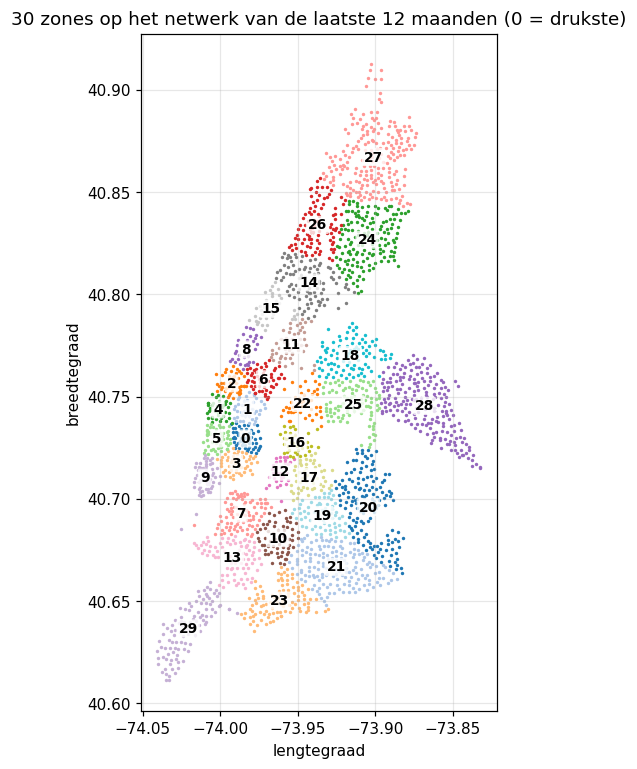

In [15]:
kmeans = cb.fit_zones(current, cb.N_ZONES)
zones = cb.zone_table(current, kmeans)
current = current.assign(zone=cb.assign_zones(current, kmeans, zones).to_numpy())
fig, ax = plt.subplots(figsize=(7, 8))
cmap = plt.get_cmap("tab20")
for z in zones["zone"]:
    part = current[current["zone"] == z]
    ax.scatter(part["lng"], part["lat"], s=5, color=cmap(z % 20), lw=0)
for _, z in zones.iterrows():
    ax.text(z["lng"], z["lat"], str(z["zone"]), fontsize=9, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.8))
ax.set(title="30 zones op het netwerk van de laatste 12 maanden (0 = drukste)", xlabel="lengtegraad", ylabel="breedtegraad")
ax.set_aspect(1 / np.cos(np.radians(40.73)))
plt.show()

## 11. Het netwerk groeit: aanbod als kenmerk
**Vaststelling:** het aantal stations met minstens één vertrek groeide sterk.

In [16]:
active = (ids_per_month.assign(loc=ids_per_month["start_station_id"].map(location))
          .loc[lambda d: d["start_station_id"].isin(public_ids)].groupby("m")["loc"].nunique())
yearly = active.groupby(active.index.year).mean().round()
yearly.to_frame("gemiddeld aantal actieve stations per maand").T

m,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
gemiddeld aantal actieve stations per maand,330.0,329.0,380.0,525.0,652.0,762.0,805.0,1002.0,1423.0,1581.0,1896.0,2130.0,2154.0,2265.0


**Keuze:**
- per zone en per maand het aantal **actieve stations** (unieke locaties met minstens één vertrek) toevoegen als **kenmerk**;
- **zone-uren zonder enig actief station weglaten**.

**Waarom:** veel zones bestonden in de eerste jaren nog niet (de Bronx en Queens kregen pas tussen 2019 en 2023 stations). Een zone-uur zonder station is geen "0 vraag" maar "geen aanbod". En een zone met 20 stations vraagt minder fietsen dan dezelfde zone met 150 stations: zonder dat kenmerk kan het model de groei niet volgen. Bij een voorspelling voor de toekomst gebruikt de API het **huidige** aantal actieve stations per zone.

## 12–14. Rooster, weer en split
**12. Volledig rooster.** `station_hour` bevat alleen uren met minstens één vertrek. Voor het model moeten ook de uren **zonder** vertrek erin staan (als 0), anders leert het alleen van uren met vraag en overschat het altijd. We bouwen daarom elke combinatie zone × uur en vullen de gaten met 0.

**13. Weer.** Het weer is de grootste factor buiten de kalender (in `02` toetsen we dat). We halen per uur temperatuur, neerslag, wind, sneeuwval, luchtvochtigheid en **sneeuwhoogte** op bij Open-Meteo (gratis archief van weermodellen), voor één punt in het midden van NYC, in **lokale tijd** zoals de ritdata. Door de zomertijd ontbreekt in maart één uur en komt in november één uur dubbel voor: we ontdubbelen en vullen dat ene uur met interpolatie. De sneeuwhoogte kwam er later bij: de foutenanalyse in `02` toonde dat het model de vraag overschatte op droge dagen ná een sneeuwstorm, als er nog sneeuw lag.

**14. Split.** De **testset** is de laatste 12 maanden (oktober 2025 – september 2026): zo meten we zoals het model gebruikt wordt (getraind op het verleden, voorspellend voor de toekomst), en zit elk seizoen er één keer in. Voor het kiezen en tunen gebruiken we binnen de trainset **backtesting** (3 folds: trainen op alle jaren vóór een validatiejaar, valideren op dat jaar), zie `02`.

In [17]:
table, zones, public_stations = cb.prepare_full_table(cb.DATA_DIR / "station_hour", stations, weather,
                                                      exclude_days=cb.EXCLUDE_DAYS)
print(f"Modeltabel: {len(table):,} zone-uren van {table['time'].min()} tot {table['time'].max()}")
print(f"Uren zonder vertrek: {(table['trips'] == 0).mean():.1%}; gemiddeld {table['trips'].mean():.1f} vertrekken per zone-uur")
table.head()

Modeltabel: 2,818,992 zone-uren van 2013-06-01 00:00:00 tot 2026-09-30 23:00:00
Uren zonder vertrek: 4.2%; gemiddeld 116.6 vertrekken per zone-uur


,zone,time,trips,members,electric,active_stations,temperature_c,precipitation_mm,wind_kmh,snowfall_cm,humidity_pct,snow_depth_cm,split
0,0,2013-06-01 00:00:00,24,21,0,32,22.7,0.0,11.2,0.0,65,0.0,train
1,0,2013-06-01 01:00:00,10,9,0,32,21.9,0.0,10.5,0.0,70,0.0,train
2,0,2013-06-01 02:00:00,7,4,0,32,21.2,0.0,10.5,0.0,75,0.0,train
3,0,2013-06-01 03:00:00,8,3,0,32,20.6,0.0,9.7,0.0,78,0.0,train
4,0,2013-06-01 04:00:00,2,2,0,32,20.1,0.0,9.7,0.0,83,0.0,train


## 15. Controles
1. Geen dubbele (zone, uur)-rijen en geen ontbrekende waarden.
2. **Er gaan geen vertrekken verloren**, behalve op de 12 gesloten dagen: de som van `trips` is gelijk aan alle vertrekken van de publieke stations op de overige dagen.
3. Elke rij heeft minstens één actief station.
4. De testset beslaat de laatste 12 maanden.

In [18]:
assert not table.duplicated(["zone", "time"]).any()
assert table.notna().all().all(), table.isna().sum()
assert (table["active_stations"] > 0).all()
kept = set(public_stations["start_station_id"])
excluded = pd.to_datetime(cb.EXCLUDE_DAYS)
expected = 0
for path in sorted((cb.DATA_DIR / "station_hour").glob("*.parquet")):
    sh = pd.read_parquet(path, columns=["start_station_id", "time", "trips"])
    expected += sh.loc[sh["start_station_id"].isin(kept) & ~sh["time"].dt.normalize().isin(excluded), "trips"].sum()
assert table["trips"].sum() == expected, (table["trips"].sum(), expected)
test = table[table["split"] == "test"]
print(f"OK: {len(table):,} rijen, {table['trips'].sum():,} vertrekken "
      f"({table['trips'].sum() / audit['rows'].sum():.2%} van alle ruwe ritten); "
      f"test {test['time'].min():%Y-%m-%d} t/m {test['time'].max():%Y-%m-%d} ({len(test) / len(table):.1%})")

OK: 2,818,992 rijen, 328,688,926 vertrekken (99.97% van alle ruwe ritten); test 2025-10-01 t/m 2026-09-30 (9.3%)


## 16. Opslaan

In [19]:
columns = ["zone", "time", "trips", "members", "electric", "active_stations", "temperature_c", "precipitation_mm",
           "wind_kmh", "snowfall_cm", "snow_depth_cm", "humidity_pct", "split"]
table = table[columns].astype({"zone": "int16", "trips": "int32", "members": "int32", "electric": "int32",
                               "active_stations": "int16"})
table.to_parquet(cb.DATA_DIR / "model_table.parquet", index=False)
zones_records = zones.assign(lat=zones["lat"].round(5), lng=zones["lng"].round(5)).to_dict("records")
(cb.DATA_DIR / "zones.json").write_text(json.dumps(zones_records, indent=2, default=int), encoding="utf-8")
public_stations.to_parquet(cb.DATA_DIR / "station_zones.parquet", index=False)
print(f"model_table.parquet: {(cb.DATA_DIR / 'model_table.parquet').stat().st_size / 1e6:.1f} MB")

model_table.parquet: 27.8 MB


## Samenvatting
| | |
|---|---|
| Ruwe data | 44 bestanden, 32,5 GB, **328,8 miljoen ritten** (juni 2013 – september 2026) |
| Bruikbaar als vertrek | 99,97% |
| Weggelaten | 21 dubbele CSV-versies, ritten zonder startlocatie (0,03%), 110 interne/JC-stations (0,006%), 12 gesloten dagen |
| Bewust **niet** weggelaten | ritten zonder einde, lange en negatieve ritduren, "dubbele" rijen uit 2013–2017 |
| Herstelde gegevens | drie generaties kolomnamen, drie datumnotaties, station-id's die als getal waren opgeslagen |
| Modeltabel | **2.818.992 zone-uren** (30 zones × uren met aanbod), 328,7 miljoen vertrekken, gemiddeld 117 per zone-uur, 4% zonder vertrek |
| Kenmerken klaar voor het model | zone, kalender, weer (incl. sneeuwhoogte), jaar, actieve stations |
| Test | oktober 2025 – september 2026 (9,3% van de rijen) |

Elke stap is gecontroleerd: geen vertrek gaat verloren behalve op de gesloten dagen. Volgende stap: `02_analyse_en_modellen.ipynb`.